# Lecture 14 Notebook

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
mpg = pd.read_csv('mpg.csv')
mpg.tail()

,Unnamed: 0,manufacturer,model,displ,year,cyl,trans,drv,cty,hwy,fl,class
229,230,volkswagen,passat,2.0,2008,4,auto(s6),f,19,28,p,midsize
230,231,volkswagen,passat,2.0,2008,4,manual(m6),f,21,29,p,midsize
231,232,volkswagen,passat,2.8,1999,6,auto(l5),f,16,26,p,midsize
232,233,volkswagen,passat,2.8,1999,6,manual(m5),f,18,26,p,midsize
233,234,volkswagen,passat,3.6,2008,6,auto(s6),f,17,26,p,midsize


In [20]:
mpg

,Unnamed: 0,manufacturer,model,displ,year,cyl,trans,drv,cty,hwy,fl,class
0,1,audi,a4,1.8,1999,4,auto(l5),f,18,29,p,compact
1,2,audi,a4,1.8,1999,4,manual(m5),f,21,29,p,compact
2,3,audi,a4,2.0,2008,4,manual(m6),f,20,31,p,compact
3,4,audi,a4,2.0,2008,4,auto(av),f,21,30,p,compact
4,5,audi,a4,2.8,1999,6,auto(l5),f,16,26,p,compact
...,...,...,...,...,...,...,...,...,...,...,...,...
229,230,volkswagen,passat,2.0,2008,4,auto(s6),f,19,28,p,midsize
230,231,volkswagen,passat,2.0,2008,4,manual(m6),f,21,29,p,midsize
231,232,volkswagen,passat,2.8,1999,6,auto(l5),f,16,26,p,midsize
232,233,volkswagen,passat,2.8,1999,6,manual(m5),f,18,26,p,midsize


In [21]:
mpg.head()

,Unnamed: 0,manufacturer,model,displ,year,cyl,trans,drv,cty,hwy,fl,class
0,1,audi,a4,1.8,1999,4,auto(l5),f,18,29,p,compact
1,2,audi,a4,1.8,1999,4,manual(m5),f,21,29,p,compact
2,3,audi,a4,2.0,2008,4,manual(m6),f,20,31,p,compact
3,4,audi,a4,2.0,2008,4,auto(av),f,21,30,p,compact
4,5,audi,a4,2.8,1999,6,auto(l5),f,16,26,p,compact


In [22]:
mpg.shape

(234, 12)

In [23]:
mpg.info

<bound method DataFrame.info of      Unnamed: 0 manufacturer   model  displ  year  cyl       trans drv  cty  \
0             1         audi      a4    1.8  1999    4    auto(l5)   f   18   
1             2         audi      a4    1.8  1999    4  manual(m5)   f   21   
2             3         audi      a4    2.0  2008    4  manual(m6)   f   20   
3             4         audi      a4    2.0  2008    4    auto(av)   f   21   
4             5         audi      a4    2.8  1999    6    auto(l5)   f   16   
..          ...          ...     ...    ...   ...  ...         ...  ..  ...   
229         230   volkswagen  passat    2.0  2008    4    auto(s6)   f   19   
230         231   volkswagen  passat    2.0  2008    4  manual(m6)   f   21   
231         232   volkswagen  passat    2.8  1999    6    auto(l5)   f   16   
232         233   volkswagen  passat    2.8  1999    6  manual(m5)   f   18   
233         234   volkswagen  passat    3.6  2008    6    auto(s6)   f   17   

     hwy fl    clas

The pairplot indicates that 

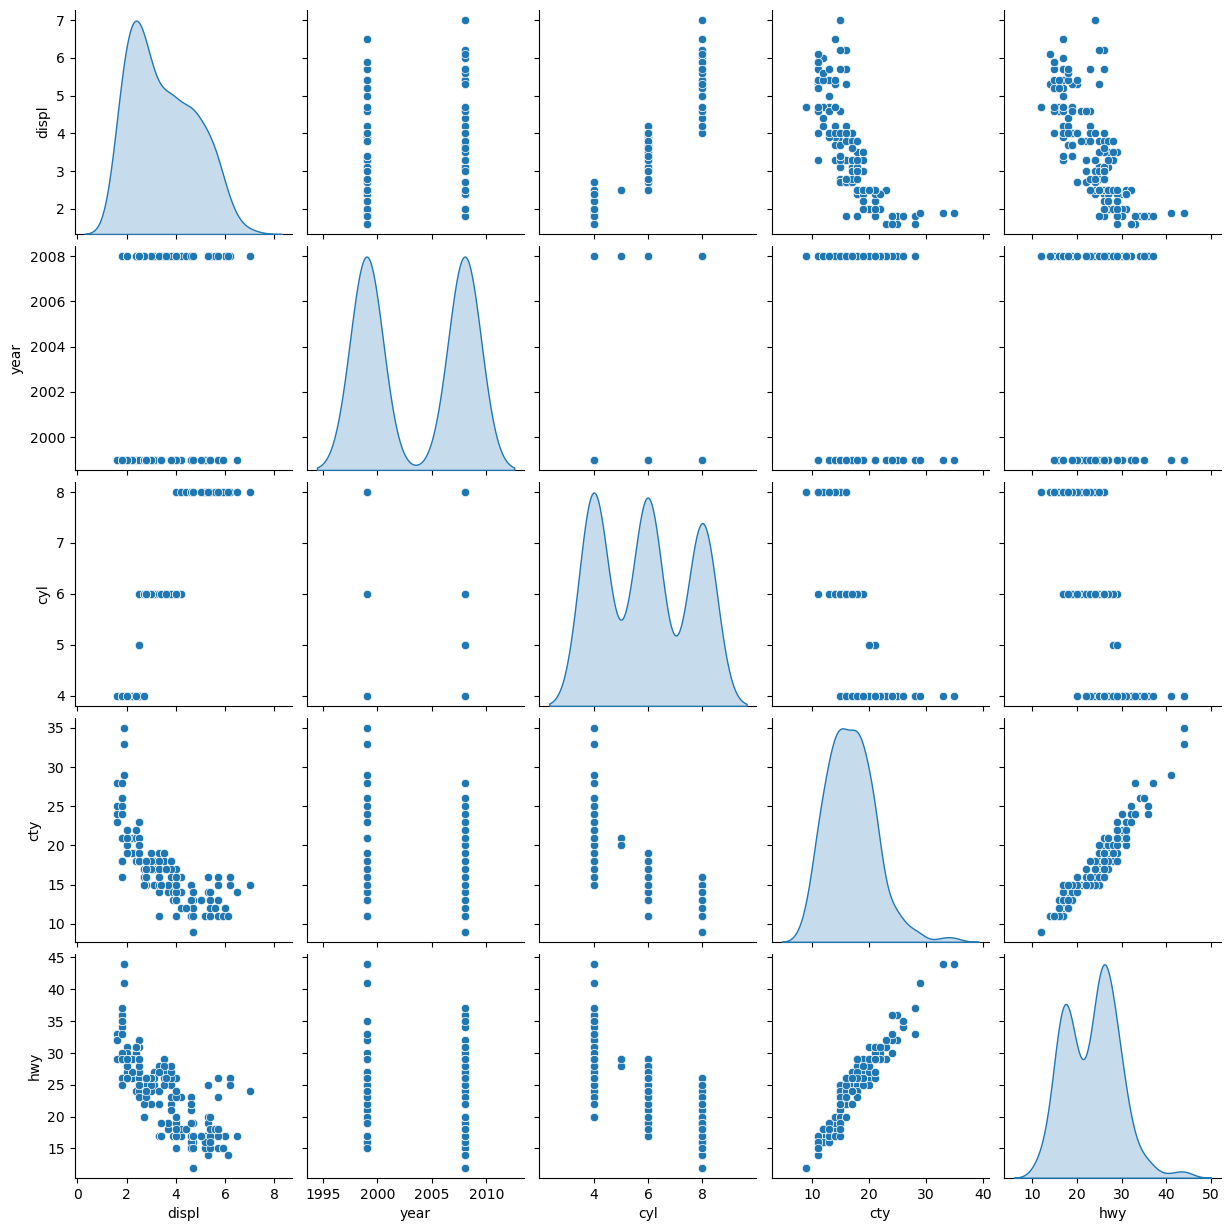

In [24]:
import seaborn as sns
sns.pairplot(data = mpg, y_vars=['displ', 'year', 'cyl', 'cty', 'hwy'], x_vars=['displ', 'year', 'cyl', 'cty', 'hwy'], diag_kind='kde')

In [25]:
mpg[['displ', 'year', 'cyl', 'cty', 'hwy']].corr()

,displ,year,cyl,cty,hwy
displ,1.000000,0.147843,0.930227,-0.798524,-0.766020
year,0.147843,1.000000,0.122245,-0.037232,0.002158
cyl,0.930227,0.122245,1.000000,-0.805771,-0.761912
cty,-0.798524,-0.037232,-0.805771,1.000000,0.955916
hwy,-0.766020,0.002158,-0.761912,0.955916,1.000000


<Axes: >

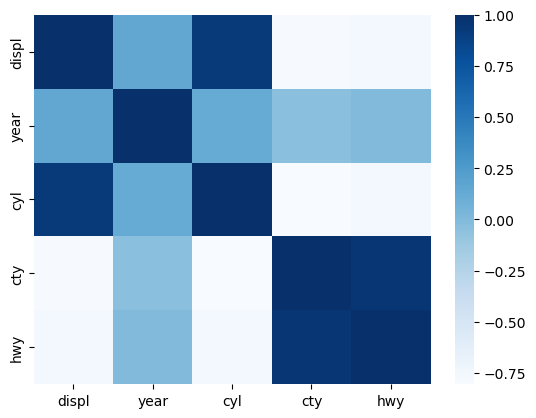

In [26]:
mpg2 = mpg[['displ', 'year', 'cyl', 'cty', 'hwy']]
sns.heatmap(data=mpg2.corr(), cmap = 'Blues')

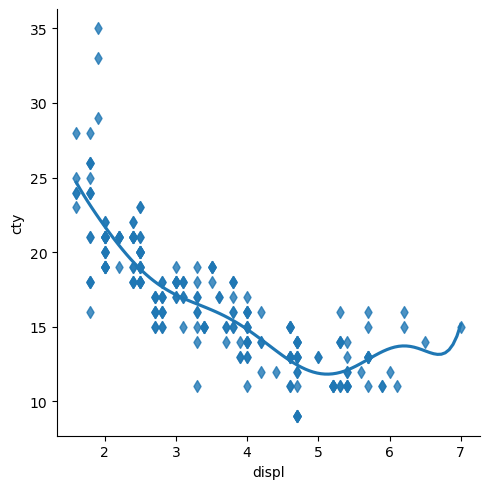

In [27]:
sns.lmplot(data=mpg, x = 'displ', y = 'cty', ci = None, markers = 'd', order = 8)



In [28]:
import statsmodels.formula.api as smf
result=smf.ols(formula='cty ~ cyl', data= mpg).fit()
result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    cty   R-squared:                       0.649
Model:                            OLS   Adj. R-squared:                  0.648
Method:                 Least Squares   F-statistic:                     429.5
Date:                Wed, 22 Oct 2025   Prob (F-statistic):           1.07e-54
Time:                        14:11:59   Log-Likelihood:                -547.85
No. Observations:                 234   AIC:                             1100.
Df Residuals:                     232   BIC:                             1107.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     29.3904      0.627     46.887      0.000      28.155      30.625
cyl           -2.1280      0.103    -20.724      0.000      -2.330      -1.926
==============================================================================
Omnibus:                       85.825   Durbin-Watson:                   1.100
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              415.701
Skew:                           1.381   Prob(JB):                     5.39e-91
Kurtosis:                       8.917   Cond. No.                         23.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [29]:
result1=smf.ols(formula='hwy ~ drv', data= mpg).fit()
result1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    hwy   R-squared:                       0.531
Model:                            OLS   Adj. R-squared:                  0.527
Method:                 Least Squares   F-statistic:                     130.6
Date:                Wed, 22 Oct 2025   Prob (F-statistic):           1.13e-38
Time:                        14:11:59   Log-Likelihood:                -660.51
No. Observations:                 234   AIC:                             1327.
Df Residuals:                     231   BIC:                             1337.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     19.1748      0.404     47.501      0.000      18.379      19.970
drv[T.f]       8.9856      0.567     15.852      0.000       7.869      10.102
drv[T.r]       1.8252      0.913      1.998      0.047       0.026       3.625
==============================================================================
Omnibus:                       30.603   Durbin-Watson:                   0.792
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               42.452
Skew:                           0.822   Prob(JB):                     6.05e-10
Kurtosis:                       4.285   Cond. No.                         4.06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [30]:
result1=smf.ols(formula='hwy ~ cty', data= mpg).fit()
result1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    hwy   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     2459.
Date:                Wed, 22 Oct 2025   Prob (F-statistic):          1.87e-125
Time:                        14:11:59   Log-Likelihood:                -462.28
No. Observations:                 234   AIC:                             928.6
Df Residuals:                     232   BIC:                             935.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.8920      0.469      1.902      0.058      -0.032       1.816
cty            1.3375      0.027     49.585      0.000       1.284       1.391
==============================================================================
Omnibus:                        1.055   Durbin-Watson:                   1.006
Prob(Omnibus):                  0.590   Jarque-Bera (JB):                0.879
Skew:                           0.147   Prob(JB):                        0.644
Kurtosis:                       3.058   Cond. No.                         71.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [31]:
result1=smf.ols(formula='hwy ~ year', data= mpg).fit()
result1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    hwy   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.004
Method:                 Least Squares   F-statistic:                  0.001080
Date:                Wed, 22 Oct 2025   Prob (F-statistic):              0.974
Time:                        14:11:59   Log-Likelihood:                -749.03
No. Observations:                 234   AIC:                             1502.
Df Residuals:                     232   BIC:                             1509.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     17.7322    173.684      0.102      0.919    -324.466     359.931
year           0.0028      0.087      0.033      0.974      -0.168       0.174
==============================================================================
Omnibus:                        5.793   Durbin-Watson:                   0.472
Prob(Omnibus):                  0.055   Jarque-Bera (JB):                5.528
Skew:                           0.367   Prob(JB):                       0.0630
Kurtosis:                       3.167   Cond. No.                     8.92e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 8.92e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [32]:
result1=smf.ols(formula='hwy ~ displ', data= mpg).fit()
result1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    hwy   R-squared:                       0.587
Model:                            OLS   Adj. R-squared:                  0.585
Method:                 Least Squares   F-statistic:                     329.5
Date:                Wed, 22 Oct 2025   Prob (F-statistic):           2.04e-46
Time:                        14:11:59   Log-Likelihood:                -645.62
No. Observations:                 234   AIC:                             1295.
Df Residuals:                     232   BIC:                             1302.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     35.6977      0.720     49.555      0.000      34.278      37.117
displ         -3.5306      0.195    -18.151      0.000      -3.914      -3.147
==============================================================================
Omnibus:                       45.280   Durbin-Watson:                   0.954
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               90.192
Skew:                           0.961   Prob(JB):                     2.60e-20
Kurtosis:                       5.357   Cond. No.                         11.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [33]:
result1=smf.ols(formula='hwy ~ cyl', data= mpg).fit()
result1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    hwy   R-squared:                       0.581
Model:                            OLS   Adj. R-squared:                  0.579
Method:                 Least Squares   F-statistic:                     321.1
Date:                Wed, 22 Oct 2025   Prob (F-statistic):           1.18e-45
Time:                        14:11:59   Log-Likelihood:                -647.39
No. Observations:                 234   AIC:                             1299.
Df Residuals:                     232   BIC:                             1306.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     40.0190      0.959     41.724      0.000      38.129      41.909
cyl           -2.8153      0.157    -17.918      0.000      -3.125      -2.506
==============================================================================
Omnibus:                       19.977   Durbin-Watson:                   0.877
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               31.847
Skew:                           0.512   Prob(JB):                     1.21e-07
Kurtosis:                       4.489   Cond. No.                         23.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [34]:
result=smf.ols(formula='cty ~ displ', data= mpg).fit()
result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    cty   R-squared:                       0.638
Model:                            OLS   Adj. R-squared:                  0.636
Method:                 Least Squares   F-statistic:                     408.2
Date:                Wed, 22 Oct 2025   Prob (F-statistic):           4.74e-53
Time:                        14:11:59   Log-Likelihood:                -551.67
No. Observations:                 234   AIC:                             1107.
Df Residuals:                     232   BIC:                             1114.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     25.9915      0.482     53.908      0.000      25.042      26.941
displ         -2.6305      0.130    -20.205      0.000      -2.887      -2.374
==============================================================================
Omnibus:                       86.751   Durbin-Watson:                   1.158
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              372.373
Skew:                           1.447   Prob(JB):                     1.38e-81
Kurtosis:                       8.460   Cond. No.                         11.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [35]:
resultd=smf.ols(formula='cty ~ drv', data= mpg).fit()
resultd.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    cty   R-squared:                       0.445
Model:                            OLS   Adj. R-squared:                  0.440
Method:                 Least Squares   F-statistic:                     92.68
Date:                Wed, 22 Oct 2025   Prob (F-statistic):           2.82e-30
Time:                        14:11:59   Log-Likelihood:                -601.51
No. Observations:                 234   AIC:                             1209.
Df Residuals:                     231   BIC:                             1219.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     14.3301      0.314     45.680      0.000      13.712      14.948
drv[T.f]       5.6416      0.440     12.807      0.000       4.774       6.510
drv[T.r]      -0.2501      0.710     -0.352      0.725      -1.649       1.148
==============================================================================
Omnibus:                       50.742   Durbin-Watson:                   0.861
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              109.650
Skew:                           1.036   Prob(JB):                     1.55e-24
Kurtosis:                       5.637   Cond. No.                         4.06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [36]:
resultm=smf.ols(formula='cty ~ cyl + displ + drv', data= mpg).fit()
resultm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    cty   R-squared:                       0.735
Model:                            OLS   Adj. R-squared:                  0.731
Method:                 Least Squares   F-statistic:                     158.9
Date:                Wed, 22 Oct 2025   Prob (F-statistic):           7.33e-65
Time:                        14:11:59   Log-Likelihood:                -514.99
No. Observations:                 234   AIC:                             1040.
Df Residuals:                     229   BIC:                             1057.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     25.7046      0.767     33.502      0.000      24.193      27.216
drv[T.f]       2.5021      0.382      6.547      0.000       1.749       3.255
drv[T.r]       2.1714      0.530      4.099      0.000       1.128       3.215
cyl           -1.2981      0.248     -5.230      0.000      -1.787      -0.809
displ         -0.7393      0.343     -2.152      0.032      -1.416      -0.062
==============================================================================
Omnibus:                      113.810   Durbin-Watson:                   1.374
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              847.809
Skew:                           1.751   Prob(JB):                    7.96e-185
Kurtosis:                      11.643   Cond. No.                         40.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""